# Model Evaluation and Interpretation

## Objective

This notebook evaluates the final selected machine learning models developed
for predicting natural fibre composite mechanical properties.

The selected models from Notebook 04 are analysed using:

- Regression performance metrics
- Prediction accuracy plots
- Residual analysis
- Feature importance analysis

The objective is to understand both model performance and the influence of
material characteristics on Tensile Strength and Elastic Modulus.

In [24]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt


import joblib


from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)


from sklearn.inspection import permutation_importance


import warnings

warnings.filterwarnings("ignore")

In [25]:
df = pd.read_csv(
    "../data/cleaned/cleaned_dataset.csv"
)


df.head()

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa
0,Flax,Epoxy,0,0 UD,3.0,0.3,20042.2367,297.4065
1,Flax,Epoxy,0,0 UD,3.0,0.3,19701.1091,289.9346
2,Flax,Epoxy,0,0 UD,3.0,0.3,17559.1106,274.8862
3,Flax,Epoxy,0,0 UD,3.0,0.3,19737.9379,277.5509
4,Flax,Epoxy,0,0 UD,3.0,0.3,18048.3804,286.1064


In [26]:
tensile_model = joblib.load(
    "../models/tensile_strength_model.pkl"
)


modulus_model = joblib.load(
    "../models/elastic_modulus_model.pkl"
)

In [27]:
features = [

    "fiber_type",

    "matrix_type",

    "fiber_volume_fraction",

    "num_plies",

    "orientation",

    "fiber_configuration"

]


X = df[features]


y_strength = df[
    "tensile_strength_mpa"
]


y_modulus = df[
    "elastic_modulus_mpa"
]

# PART A — Final Model Performance

In [28]:
strength_predictions = tensile_model.predict(
    X
)

In [29]:
strength_r2 = r2_score(
    y_strength,
    strength_predictions
)


strength_mae = mean_absolute_error(
    y_strength,
    strength_predictions
)


strength_rmse = np.sqrt(
    mean_squared_error(
        y_strength,
        strength_predictions
    )
)


print("Tensile Strength Model")

print("R²:", strength_r2)

print("MAE:", strength_mae)

print("RMSE:", strength_rmse)

Tensile Strength Model
R²: 0.9900370518124147
MAE: 4.85104783863849
RMSE: 7.7565366330089205


In [30]:
modulus_predictions = modulus_model.predict(
    X
)

In [31]:
modulus_r2 = r2_score(
    y_modulus,
    modulus_predictions
)


modulus_mae = mean_absolute_error(
    y_modulus,
    modulus_predictions
)


modulus_rmse = np.sqrt(
    mean_squared_error(
        y_modulus,
        modulus_predictions
    )
)


print("Elastic Modulus Model")

print("R²:", modulus_r2)

print("MAE:", modulus_mae)

print("RMSE:", modulus_rmse)

Elastic Modulus Model
R²: 0.9754778212476766
MAE: 463.4872466419528
RMSE: 651.8967523554737


# PART B — Prediction Visualisation

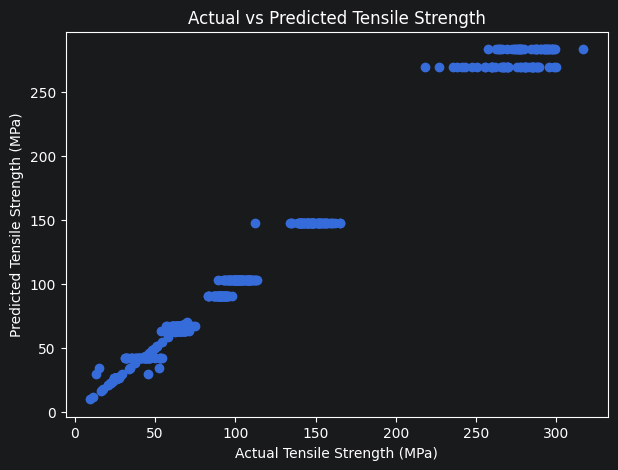

In [32]:
plt.figure(figsize=(7,5))


plt.scatter(
    y_strength,
    strength_predictions
)


plt.xlabel(
    "Actual Tensile Strength (MPa)"
)


plt.ylabel(
    "Predicted Tensile Strength (MPa)"
)


plt.title(
    "Actual vs Predicted Tensile Strength"
)


plt.show()

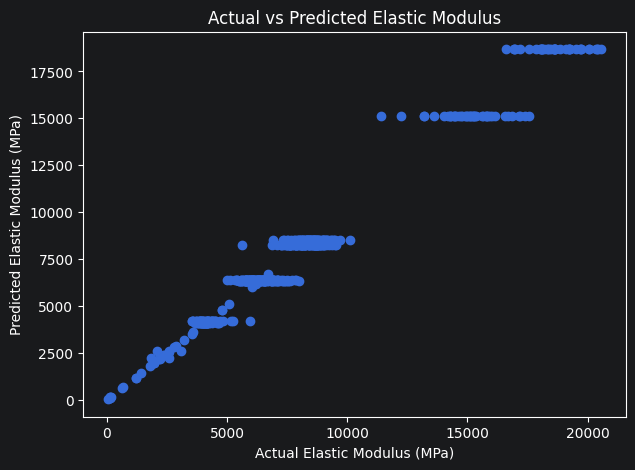

In [33]:
plt.figure(figsize=(7,5))


plt.scatter(
    y_modulus,
    modulus_predictions
)


plt.xlabel(
    "Actual Elastic Modulus (MPa)"
)


plt.ylabel(
    "Predicted Elastic Modulus (MPa)"
)


plt.title(
    "Actual vs Predicted Elastic Modulus"
)


plt.show()

# PART C — Residual Analysis

In [34]:
strength_residuals = (
    y_strength -
    strength_predictions
)

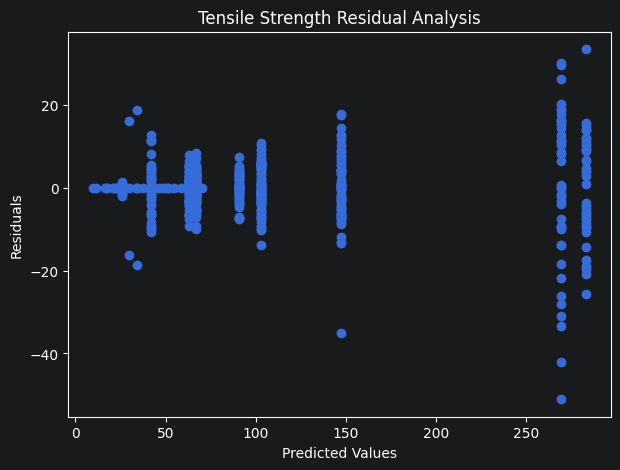

In [35]:
plt.figure(figsize=(7,5))


plt.scatter(
    strength_predictions,
    strength_residuals
)


plt.xlabel(
    "Predicted Values"
)


plt.ylabel(
    "Residuals"
)


plt.title(
    "Tensile Strength Residual Analysis"
)


plt.show()

In [36]:
modulus_residuals = (
    y_modulus -
    modulus_predictions
)

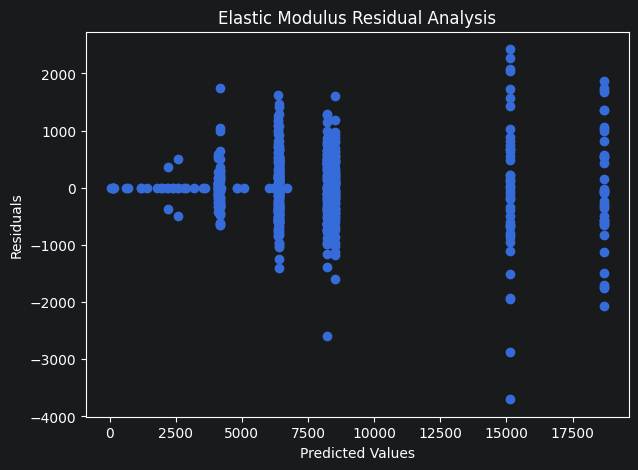

In [37]:
plt.figure(figsize=(7,5))


plt.scatter(
    modulus_predictions,
    modulus_residuals
)


plt.xlabel(
    "Predicted Values"
)


plt.ylabel(
    "Residuals"
)


plt.title(
    "Elastic Modulus Residual Analysis"
)


plt.show()

# PART D — Feature Importance

In [38]:
importance_strength = permutation_importance(

    tensile_model,

    X,

    y_strength,

    n_repeats=10,

    random_state=42

)

In [39]:
strength_importance_df = pd.DataFrame({

    "Feature":
    features,

    "Importance":
    importance_strength.importances_mean

})


strength_importance_df.sort_values(

    by="Importance",

    ascending=False

)

,Feature,Importance
4,orientation,1.709117
0,fiber_type,0.741717
2,fiber_volume_fraction,0.066679
1,matrix_type,0.004163
5,fiber_configuration,0.000248
3,num_plies,0.000006


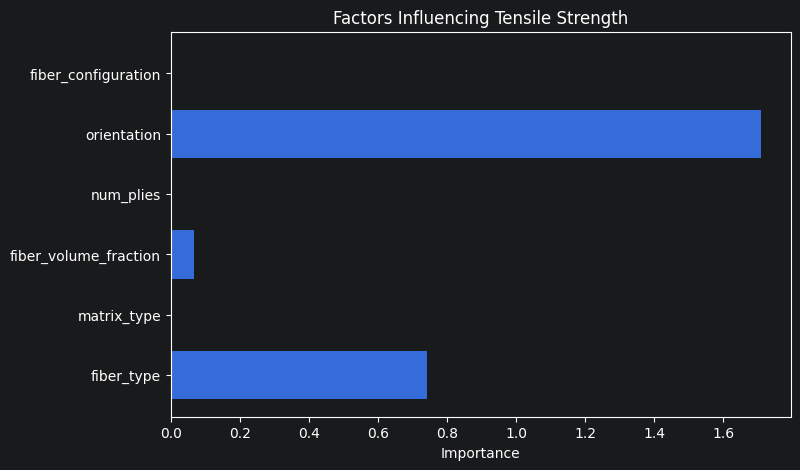

In [40]:
plt.figure(figsize=(8,5))


plt.barh(

    strength_importance_df["Feature"],

    strength_importance_df["Importance"]

)


plt.xlabel(
    "Importance"
)


plt.title(
    "Factors Influencing Tensile Strength"
)


plt.show()

In [41]:
importance_modulus = permutation_importance(

    modulus_model,

    X,

    y_modulus,

    n_repeats=10,

    random_state=42

)

In [42]:
modulus_importance_df = pd.DataFrame({

    "Feature":
    features,

    "Importance":
    importance_modulus.importances_mean

})


modulus_importance_df.sort_values(

    by="Importance",

    ascending=False

)

,Feature,Importance
4,orientation,1.769402e+00
0,fiber_type,8.253702e-01
2,fiber_volume_fraction,6.733580e-02
1,matrix_type,5.989220e-02
3,num_plies,1.397016e-05
5,fiber_configuration,-7.596486e-07


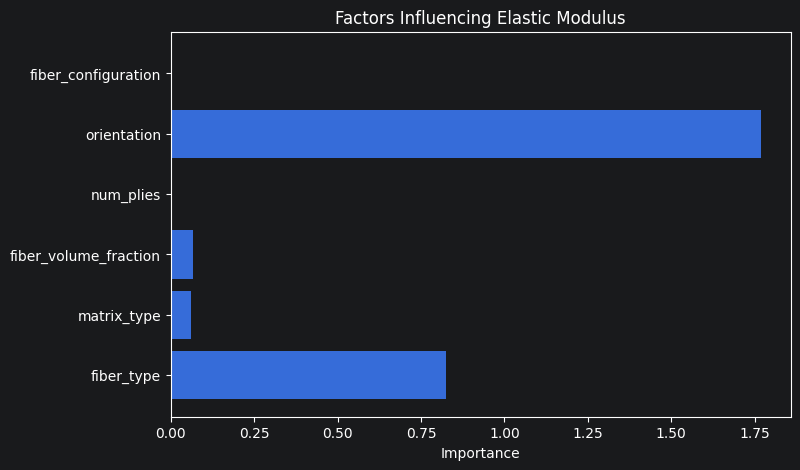

In [43]:
plt.figure(figsize=(8,5))


plt.barh(

    modulus_importance_df["Feature"],

    modulus_importance_df["Importance"]

)


plt.xlabel(
    "Importance"
)


plt.title(
    "Factors Influencing Elastic Modulus"
)


plt.show()

In [44]:
final_results = pd.DataFrame({

    "Property":

    [
        "Tensile Strength",
        "Elastic Modulus"
    ],


    "R2":

    [
        strength_r2,
        modulus_r2
    ],


    "MAE":

    [
        strength_mae,
        modulus_mae
    ],


    "RMSE":

    [
        strength_rmse,
        modulus_rmse
    ]

})


final_results

,Property,R2,MAE,RMSE
0,Tensile Strength,0.990037,4.851048,7.756537
1,Elastic Modulus,0.975478,463.487247,651.896752


In [45]:
final_results.to_csv(
    "../data/results/final_model_results.csv",
    index=False
)

# Final Analysis Summary

The selected machine learning models were evaluated using regression
performance metrics.

The models demonstrated their ability to predict:

- Tensile Strength
- Elastic Modulus

Prediction accuracy was assessed using:

- R² Score
- MAE
- RMSE

Feature importance analysis showed which material characteristics contributed
most strongly to composite mechanical behaviour.

The final trained models are ready for integration into a prediction
application.